# Padding trên bộ test

Đọc test parquet, chạy 6 kịch bản Padding, kiểm tra integrity và xuất Parquet gốc + NPZ đã scale.

**Để ý:** `TEST_PARQUET` phải là dữ liệu chưa scale. `SCALER_PATH` phải là scaler fit trên tập train tương ứng với model/bộ chia dữ liệu mới. Không fit scaler trên test và không mặc định dùng scaler cũ.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, json, joblib, zlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ===== SỬA CÁC ĐƯỜNG DẪN =====
TEST_PARQUET = "/content/test.parquet"
OUTPUT_DIR   = "/content/drive/MyDrive/NTTU/HK1-2027/TTTN/[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/04_Quality_Assurance_QC/tạo biến đổi feature/day_based/1_11/perturbed_test"
CONFIG_PATH  = "/content/config.json"  # None nếu không có
SCALER_PATH  = "/content/scaler_day_based_82.joblib" # scaler của train mới
SAVE_SCALED  = True

PAD_LEVELS = [16, 64, 256]
PAD_MODES = ["static", "random"]
SEED = 42
os.makedirs(OUTPUT_DIR, exist_ok=True)
assert os.path.isfile(TEST_PARQUET), f"Không tìm thấy: {TEST_PARQUET}"
if CONFIG_PATH is not None: assert os.path.isfile(CONFIG_PATH), f"Không tìm thấy: {CONFIG_PATH}"
if SAVE_SCALED: assert SCALER_PATH and os.path.isfile(SCALER_PATH), "Thiếu scaler phù hợp với train mới."

## 1. Đọc test và xác định danh sách feature

In [ ]:
test = pd.read_parquet(TEST_PARQUET).reset_index(drop=True)
assert {"Label", "Label_binary"}.issubset(test.columns), "Parquet phải có Label và Label_binary."
test["Label"] = test["Label"].astype(str)
test["Label_binary"] = pd.to_numeric(test["Label_binary"], errors="raise").astype(int)
assert test["Label_binary"].isin([0, 1]).all()

if CONFIG_PATH is not None:
    with open(CONFIG_PATH, encoding="utf-8") as f: cfg = json.load(f)
    FEATURES = list(cfg["features"])
else:
    non_features = {"Label", "Label_binary", "__source_file", "__row_id", "__orig_row",
                    "__padding_applicable", "__padding_applied", "__validation_failed", "__fwd_bytes_added"}
    FEATURES = [c for c in test.columns if c not in non_features]

missing = [c for c in FEATURES if c not in test.columns]
assert not missing, f"Test thiếu feature: {missing}"
test[FEATURES] = test[FEATURES].apply(pd.to_numeric, errors="coerce")
assert np.isfinite(test[FEATURES].to_numpy(float)).all(), "Feature có NaN/Inf hoặc không phải số."
print("Shape:", test.shape, "| n_features:", len(FEATURES))
print("Attack:", int(test.Label_binary.sum()), "| Benign:", int((test.Label_binary == 0).sum()))
display(pd.Series(FEATURES, name="feature").to_frame())


Shape: (620183, 86) | n_features: 82
Attack: 102429 | Benign: 517754


,feature
0,Protocol
1,Flow Duration
2,Total Fwd Packets
3,Total Backward Packets
4,Fwd Packets Length Total
...,...
77,Idle Max
78,Idle Min
79,ICMP Code
80,ICMP Type


## 2. Nạp scaler tương ứng (không fit trên test)

In [ ]:
scaler = joblib.load(SCALER_PATH) if SAVE_SCALED else None
if scaler is not None:
    assert hasattr(scaler, "transform")
    if hasattr(scaler, "n_features_in_"):
        assert int(scaler.n_features_in_) == len(FEATURES), "Số feature không khớp scaler."
    if hasattr(scaler, "feature_names_in_"):
        assert list(scaler.feature_names_in_) == FEATURES, "Tên/thứ tự feature không khớp scaler."
    print("Đã nạp scaler:", SCALER_PATH)
else:
    print("Không xuất NPZ scaled; chỉ lưu parquet chưa scale.")


Đã nạp scaler: /content/scaler_day_based_82.joblib


## 3. Hàm Padding, kiểm định và chạy kịch bản

In [ ]:
MUTABLE = ["Fwd Packets Length Total"]
DERIVED = ["Fwd Packet Length Mean", "Packet Length Mean", "Avg Packet Size",
           "Avg Fwd Segment Size", "Flow Bytes/s"]
MODIFIABLE = MUTABLE + DERIVED

def arr(df, col):
    return pd.to_numeric(df[col], errors="coerce").to_numpy(dtype=np.float64)

def apply_padding(df, pad_bytes, mode, rng):
    req = ["Fwd Act Data Packets", "Total Fwd Packets", "Total Backward Packets",
           "Fwd Packets Length Total", "Bwd Packets Length Total", "Flow Duration",
           "Fwd Packet Length Mean", "Packet Length Mean", "Avg Packet Size",
           "Avg Fwd Segment Size", "Flow Bytes/s"]
    miss = [c for c in req if c not in df.columns]
    if miss: raise KeyError(f"Thiếu feature cần cho Padding: {miss}")
    n = len(df); out = df.copy()
    active = np.clip(arr(df, "Fwd Act Data Packets"), 0, None)
    fn = np.clip(arr(df, "Total Fwd Packets"), 0, None)
    bn = np.clip(arr(df, "Total Backward Packets"), 0, None)
    tn = fn + bn
    ft, bt = arr(df, "Fwd Packets Length Total"), arr(df, "Bwd Packets Length Total")
    fm, pm = arr(df, "Fwd Packet Length Mean"), arr(df, "Packet Length Mean")
    fmax = arr(df, "Fwd Packet Length Max") if "Fwd Packet Length Max" in df else np.full(n, np.inf)
    pmax = arr(df, "Packet Length Max") if "Packet Length Max" in df else np.full(n, np.inf)
    dur = arr(df, "Flow Duration")
    selected = np.floor(active) if mode == "static" else rng.binomial(np.floor(active).astype(np.int64), .5)
    requested = selected * float(pad_bytes)
    cap_fwd = np.maximum(0, (fmax-fm)*fn)
    cap_all = np.maximum(0, (pmax-pm)*tn)
    add = np.minimum(requested, np.minimum(cap_fwd, cap_all))
    add = np.where((active >= 1) & (fn > 0) & (tn > 0), add, 0.0)
    applicable = add > 0
    nft, ntb = ft+add, ft+add+bt
    def assign(c, v):
        if c in out.columns: out[c] = np.where(applicable, v, arr(df,c))
    assign("Fwd Packets Length Total", nft)
    nfm = np.divide(nft, fn, out=fm.copy(), where=fn>0)
    npm = np.divide(ntb, tn, out=pm.copy(), where=tn>0)
    assign("Fwd Packet Length Mean", nfm)
    assign("Avg Fwd Segment Size", nfm)
    assign("Packet Length Mean", npm)
    assign("Avg Packet Size", npm)
    old_rate = arr(df, "Flow Bytes/s")
    rate = np.divide(ntb, dur/1e6, out=old_rate.copy(), where=dur>0)
    assign("Flow Bytes/s", rate)
    return out, applicable, add

def validate(original, perturbed):
    O, P = original.to_numpy(float), perturbed.to_numpy(float)
    v = {"non_finite_new": (~np.isfinite(P).all(1)) & np.isfinite(O).all(1)}
    mut = [c for c in MODIFIABLE if c in original.columns]
    imm = [c for c in original.columns if c not in MODIFIABLE]
    if mut:
        om, pm = original[mut].to_numpy(float), perturbed[mut].to_numpy(float)
        v["negative_value_new"] = ((pm<0)&(om>=0)).any(1)
        v["modifiable_decreased"] = (pm < om-(1e-6*np.abs(om)+1e-9)).any(1)
    else:
        v["negative_value_new"] = np.zeros(len(O), bool); v["modifiable_decreased"] = np.zeros(len(O), bool)
    if imm:
        oi, pi = original[imm].to_numpy(float), perturbed[imm].to_numpy(float)
        v["immutable_changed"] = (np.abs(pi-oi) > 1e-6*np.abs(oi)+1e-9).any(1)
    else: v["immutable_changed"] = np.zeros(len(O), bool)
    order_bad = np.zeros(len(O), bool)
    for lo, mid, hi in [("Fwd Packet Length Min","Fwd Packet Length Mean","Fwd Packet Length Max"),
                        ("Packet Length Min","Packet Length Mean","Packet Length Max")]:
        if all(c in original.columns for c in (lo,mid,hi)):
            def bad(d):
                l,m,h = (d[c].to_numpy(float) for c in (lo,mid,hi))
                return (l > m+1e-6*np.abs(m)+1e-9) | (m > h+1e-6*np.abs(m)+1e-9)
            order_bad |= bad(perturbed) & ~bad(original)
    v["min_mean_max_new"] = order_bad
    return pd.DataFrame(v)

def run_padding(test, level, mode, tag):
    rng = np.random.default_rng(SEED + zlib.crc32(tag.encode()))
    attack = test.Label_binary.to_numpy(int) == 1
    pos = np.flatnonzero(attack)
    x = test.iloc[pos][FEATURES].reset_index(drop=True)
    pert, applicable, added = apply_padding(x, level, mode, rng)
    violations = validate(x, pert)
    failed = violations.any(axis=1).to_numpy()
    applied = applicable & ~failed
    values = test[FEATURES].to_numpy(float, copy=True)
    values[pos[applied]] = pert.to_numpy(float)[applied]
    out = pd.DataFrame(values, columns=FEATURES)
    out["Label"] = test.Label.to_numpy()
    out["Label_binary"] = test.Label_binary.to_numpy()
    out["__orig_row"] = np.arange(len(test))
    for name, mask in [("__padding_applicable", applicable), ("__padding_applied", applied),
                       ("__validation_failed", failed)]:
        full = np.zeros(len(test), bool); full[pos] = mask; out[name] = full
    full_add = np.zeros(len(test), float); full_add[pos] = np.where(applied, added, 0.0)
    out["__fwd_bytes_added"] = full_add
    summary = {"tag":tag, "mode":mode, "pad_bytes_per_active_packet":level,
               "n_test":len(test), "n_attack":int(attack.sum()),
               "n_attack_applicable":int(applicable.sum()), "n_attack_applied":int(applied.sum()),
               "n_attack_not_applicable":int((~applicable).sum()),
               "n_attack_validation_failed":int(failed.sum()), "n_rows_dropped":0}
    return out, summary, violations

required_padding = ["Fwd Act Data Packets","Total Fwd Packets","Total Backward Packets",
                    "Fwd Packets Length Total","Bwd Packets Length Total","Flow Duration",
                    "Fwd Packet Length Mean","Packet Length Mean","Avg Packet Size",
                    "Avg Fwd Segment Size","Flow Bytes/s"]
assert not [c for c in required_padding if c not in FEATURES], "Schema test thiếu feature bắt buộc cho Padding."

summaries, kept, violation_logs = [], {}, []
for mode in PAD_MODES:
    for level in PAD_LEVELS:
        tag = f"padding_{mode}_{level}B"
        out, s, v = run_padding(test, level, mode, tag)
        assert len(out) == len(test)
        out.to_parquet(os.path.join(OUTPUT_DIR, f"test_{tag}.parquet"), index=False)
        if scaler is not None:
            xs = scaler.transform(out[FEATURES].to_numpy(float)).astype(np.float32)
            np.savez_compressed(os.path.join(OUTPUT_DIR, f"test_{tag}_scaled.npz"),
                X_test=xs, y_test=out.Label_binary.to_numpy(int), labels=out.Label.to_numpy(str),
                padding_applicable=out.__padding_applicable.to_numpy(bool),
                padding_applied=out.__padding_applied.to_numpy(bool),
                validation_failed=out.__validation_failed.to_numpy(bool),
                orig_row=out.__orig_row.to_numpy(np.int64), feature_names=np.array(FEATURES))
        report = pd.DataFrame([{"rule":c, "n_violations":int(v[c].sum()),
                                "pct_of_rows":round(100*float(v[c].mean()),3)} for c in v])
        report.loc[len(report)] = {"rule":"ANY", "n_violations":int(v.any(axis=1).sum()),
                                   "pct_of_rows":round(100*float(v.any(axis=1).mean()),3)}
        s.update({f"viol_{r.rule}":int(r.n_violations) for r in report.itertuples(index=False)})
        summaries.append(s); kept[tag]=out; violation_logs.append((tag,report))
        print(tag, "applied", s["n_attack_applied"], "/", s["n_attack"])

summary_df = pd.DataFrame(summaries)
summary_df.to_csv(os.path.join(OUTPUT_DIR,"padding_summary.csv"),index=False)
pd.concat([r.assign(tag=t) for t,r in violation_logs],ignore_index=True).to_csv(
    os.path.join(OUTPUT_DIR,"validation_report.csv"),index=False)
with open(os.path.join(OUTPUT_DIR,"manifest.json"),"w",encoding="utf-8") as f:
    json.dump({"test_parquet":TEST_PARQUET,"config":CONFIG_PATH,
               "scaler":SCALER_PATH if SAVE_SCALED else None,"features":FEATURES,
               "pad_levels":PAD_LEVELS,"modes":PAD_MODES,"seed":SEED,
               "feature_scope":"flow_level_feature_space_padding",
               "packet_level_claim":False},f,ensure_ascii=False,indent=2)
display(summary_df)


padding_static_16B applied 96660 / 102429
padding_static_64B applied 96660 / 102429
padding_static_256B applied 96660 / 102429
padding_random_16B applied 48603 / 102429
padding_random_64B applied 48562 / 102429
padding_random_256B applied 48386 / 102429


,tag,mode,pad_bytes_per_active_packet,n_test,n_attack,n_attack_applicable,n_attack_applied,n_attack_not_applicable,n_attack_validation_failed,n_rows_dropped,viol_non_finite_new,viol_negative_value_new,viol_modifiable_decreased,viol_immutable_changed,viol_min_mean_max_new,viol_ANY
0,padding_static_16B,static,16,620183,102429,96660,96660,5769,0,0,0,0,0,0,0,0
1,padding_static_64B,static,64,620183,102429,96660,96660,5769,0,0,0,0,0,0,0,0
2,padding_static_256B,static,256,620183,102429,96660,96660,5769,0,0,0,0,0,0,0,0
3,padding_random_16B,random,16,620183,102429,48603,48603,53826,0,0,0,0,0,0,0,0
4,padding_random_64B,random,64,620183,102429,48562,48562,53867,0,0,0,0,0,0,0,0
5,padding_random_256B,random,256,620183,102429,48386,48386,54043,0,0,0,0,0,0,0,0


## 4. Integrity check cho tất cả scenario

In [ ]:
rows=[]
orig=test.reset_index(drop=True)
for tag,out in kept.items():
    benign=out.Label_binary.to_numpy(int)==0
    failed=out.__validation_failed.to_numpy(bool)
    noapp=~out.__padding_applicable.to_numpy(bool)
    changed=out.__padding_applied.to_numpy(bool)
    checks={
      "same_rows":len(out)==len(orig),
      "same_order":np.array_equal(out.__orig_row,np.arange(len(orig))),
      "same_labels":np.array_equal(out.Label,orig.Label) and np.array_equal(out.Label_binary,orig.Label_binary),
      "benign_unchanged":np.array_equal(out.loc[benign,FEATURES].to_numpy(),orig.loc[benign,FEATURES].to_numpy()),
      "not_applicable_unchanged":np.array_equal(out.loc[noapp,FEATURES].to_numpy(),orig.loc[noapp,FEATURES].to_numpy()),
      "failed_reverted":np.array_equal(out.loc[failed,FEATURES].to_numpy(),orig.loc[failed,FEATURES].to_numpy()),
      "finite":bool(np.isfinite(out[FEATURES].to_numpy(float)).all()),
      "padded_fwd_increased":bool((out.loc[changed,"Fwd Packets Length Total"].to_numpy() >
                                    orig.loc[changed,"Fwd Packets Length Total"].to_numpy()).all()) if changed.any() else True
    }
    rows.append({"scenario":tag,**checks,"ALL_PASS":all(checks.values())})
integrity_df=pd.DataFrame(rows)
display(integrity_df)
integrity_df.to_csv(os.path.join(OUTPUT_DIR,"integrity_report.csv"),index=False)
assert integrity_df.ALL_PASS.all(), "Có scenario không đạt integrity check."


,scenario,same_rows,same_order,same_labels,benign_unchanged,not_applicable_unchanged,failed_reverted,finite,padded_fwd_increased,ALL_PASS
0,padding_static_16B,True,True,True,True,True,True,True,True,True
1,padding_static_64B,True,True,True,True,True,True,True,True,True
2,padding_static_256B,True,True,True,True,True,True,True,True,True
3,padding_random_16B,True,True,True,True,True,True,True,True,True
4,padding_random_64B,True,True,True,True,True,True,True,True,True
5,padding_random_256B,True,True,True,True,True,True,True,True,True


## 5. Biểu đồ và báo cáo thay đổi feature

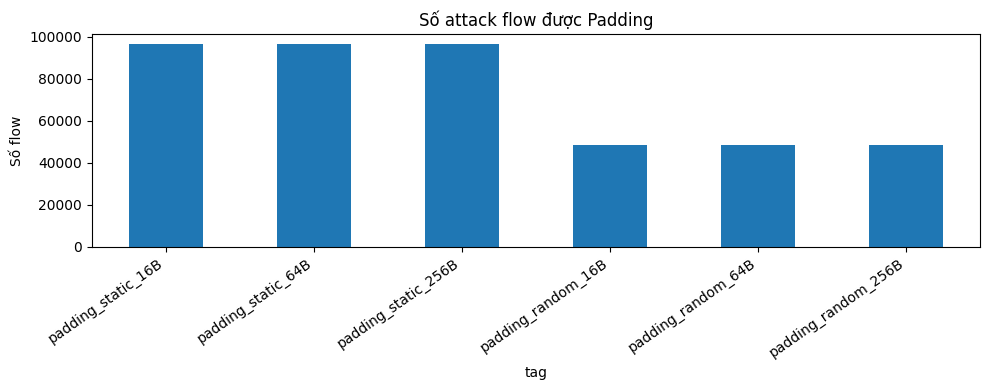

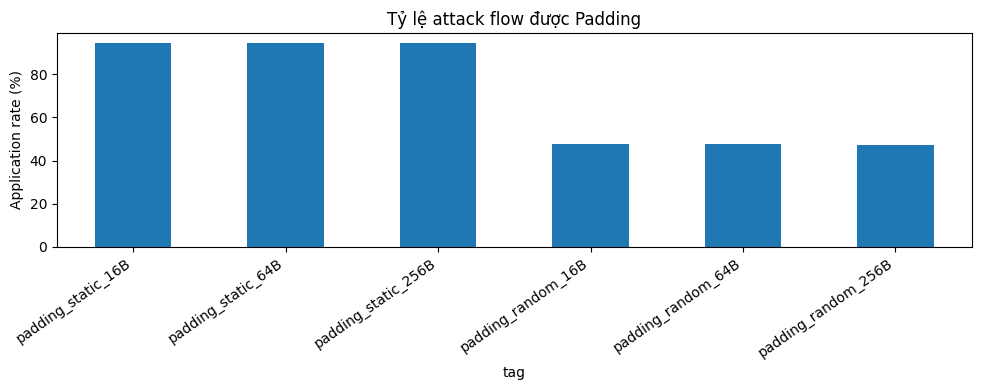

,Fwd Packets Length Total,Fwd Packet Length Mean,Packet Length Mean,Avg Packet Size,Avg Fwd Segment Size,Flow Bytes/s
padding_static_16B,1.8,1.8,1.0014,1.0014,1.8,1.0014
padding_static_64B,4.2,4.2,1.0055,1.0055,4.2,1.0055
padding_static_256B,8.0,8.0,1.0121,1.0121,8.0,1.0121
padding_random_16B,1.8,1.8,1.0014,1.0014,1.8,1.0014
padding_random_64B,4.2,4.2,1.0055,1.0055,4.2,1.0055
padding_random_256B,8.0,8.0,1.0121,1.0121,8.0,1.0121


In [ ]:
fig,ax=plt.subplots(figsize=(10,4))
summary_df.set_index("tag")["n_attack_applied"].plot(kind="bar",ax=ax)
ax.set_title("Số attack flow được Padding"); ax.set_ylabel("Số flow")
plt.xticks(rotation=35,ha="right"); plt.tight_layout(); plt.show()

rate=(summary_df.set_index("tag")["n_attack_applied"] /
      summary_df.set_index("tag")["n_attack"].replace(0,np.nan)*100)
fig,ax=plt.subplots(figsize=(10,4)); rate.plot(kind="bar",ax=ax)
ax.set_title("Tỷ lệ attack flow được Padding"); ax.set_ylabel("Application rate (%)")
plt.xticks(rotation=35,ha="right"); plt.tight_layout(); plt.show()

cols=["Fwd Packets Length Total","Fwd Packet Length Mean","Packet Length Mean",
      "Avg Packet Size","Avg Fwd Segment Size","Flow Bytes/s"]
ratios={}
for tag,out in kept.items():
    mask=out.__padding_applied.to_numpy(bool)
    if not mask.any(): ratios[tag]={c:np.nan for c in cols}; continue
    original_rows=orig.iloc[out.loc[mask,"__orig_row"].to_numpy()].reset_index(drop=True)
    changed_rows=out.loc[mask].reset_index(drop=True)
    ratios[tag]={c:float(np.median(changed_rows[c].to_numpy(float)/
                  np.maximum(np.abs(original_rows[c].to_numpy(float)),1e-9))) for c in cols}
ratio_df=pd.DataFrame(ratios).T
display(ratio_df.round(4))
ratio_df.to_csv(os.path.join(OUTPUT_DIR,"feature_change_median_ratio.csv"))


## 6. File đầu ra

- `test_padding_<mode>_<P>B.parquet`: feature đã Padding ở thang đo gốc + nhãn + cờ trạng thái.
- `test_padding_<mode>_<P>B_scaled.npz`: `X_test` đã scale bằng scaler được chỉ định, kèm nhãn và metadata (chỉ có khi `SAVE_SCALED=True`).
- `padding_summary.csv`: thống kê số flow áp dụng Padding.
- `validation_report.csv`: vi phạm validator theo scenario.
- `integrity_report.csv`: kiểm tra bảo toàn dòng, nhãn, benign, flow không áp dụng và flow lỗi.
- `feature_change_median_ratio.csv`: tỷ lệ thay đổi trung vị của các feature được cập nhật.
- `manifest.json`: lưu lại đường dẫn đầu vào, scaler và cấu hình chạy.